# Phase 1 - evaluation results

Tables and figures for the sequences folded by `hpc/eval.sh`. Nothing is sampled or folded here.

Produce the data first:

```bash
bsub < hpc/train.sh      # trains, and samples 256 sequences per architecture
bsub < hpc/eval.sh       # makes the controls, folds every set with ESMFold
```

That writes `results/eval/<set>/eval.csv`, one row per sequence with `valid`,
`nearest_identity`, `is_unique` and `mean_plddt`. This notebook reads those.

The controls are what make the numbers readable: a random sequence is perfectly novel and a
memorised one scores well on everything else, so real held-out proteins (`control_real`) and the
same proteins shuffled (`control_shuffled`) bracket the range.

In [1]:
import os
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from protgen.metrics import read_reference, set_metrics, summarize

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6"]
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#898781", "#e1e0d9", "#fcfcfb"
REAL, SHUFFLED = "#52514e", "#c3c2b7"   # controls stay grey so the models keep the colours
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "legend.frameon": False, "figure.dpi": 120,
})

frames = []
for path in sorted(Path("results/eval").glob("*/eval.csv")):
    frame = pd.read_csv(path)
    frame["setting"] = path.parent.name    # eval.py drops the column for a single set
    frames.append(frame)
if not frames:
    raise SystemExit("no results/eval/*/eval.csv - run `bsub < hpc/eval.sh` first")
table = pd.concat(frames, ignore_index=True)

# controls first, then the models
sets = sorted(table["setting"].unique(), key=lambda s: (not s.startswith("control_"), s))
folded = "mean_plddt" in table and table["mean_plddt"].notna().any()
print(f"{len(table)} sequences, {len(sets)} sets: {', '.join(sets)}")
print("pLDDT present" if folded else "no pLDDT - hpc/eval.sh folds; eval.py needs --fold")

1792 sequences, 7 sets: control_real, control_shuffled, gru, lstm, mlp, rnn, transformer
pLDDT present


## Sequence metrics

Is it a protein (`valid`), is it new (`nearest_identity`, against the training split), is it the
same one again (`is_unique`).

In [2]:
summary = summarize(table)
summary.loc[sets].round(3)

,n,frac_valid,frac_unique,nearest_identity_median
setting,,,,
control_real,256.0,1.0,1.0,0.699
control_shuffled,256.0,1.0,1.0,0.250
gru,256.0,1.0,1.0,0.566
lstm,256.0,1.0,1.0,0.583
mlp,256.0,1.0,1.0,0.248
rnn,256.0,1.0,1.0,0.475
transformer,256.0,1.0,1.0,0.647


k-mer divergence from the training distribution. Biased upwards for small sets, so compare
equal-sized sets and read it against the real control.

In [3]:
reference = read_reference("data/train.csv")
kmer = pd.DataFrame({
    name: set_metrics(group.loc[group["valid"], "sequence"], reference)
    for name, group in table.groupby("setting", sort=False)
}).T.rename_axis("setting")
kmer.loc[sets].round(4)

,n_sequences,n_reference,js_divergence_1mer,js_divergence_2mer,js_divergence_3mer
setting,,,,,
control_real,256.0,16020.0,0.0005,0.0099,0.1276
control_shuffled,256.0,16020.0,0.0005,0.0270,0.1644
gru,256.0,16020.0,0.0002,0.0035,0.0652
lstm,256.0,16020.0,0.0003,0.0038,0.0660
mlp,256.0,16020.0,0.0002,0.0039,0.0774
rnn,256.0,16020.0,0.0006,0.0053,0.0758
transformer,256.0,16020.0,0.0004,0.0048,0.0711


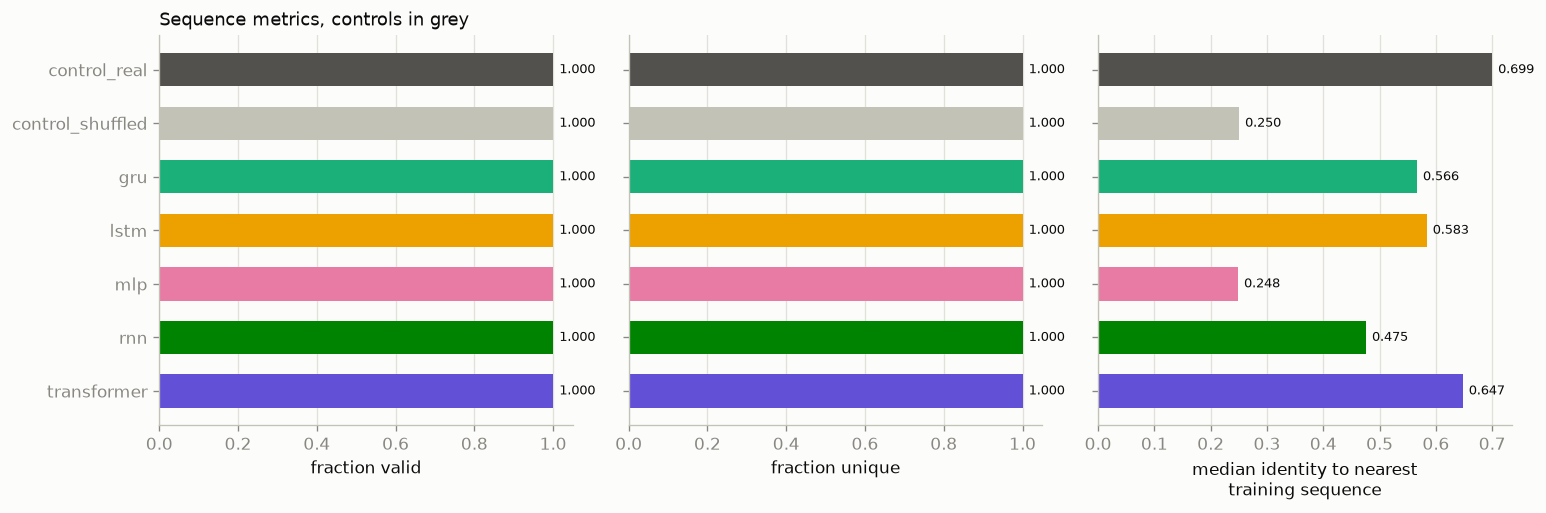

In [4]:
# one panel per metric - they do not share a scale
metrics = [("frac_valid", "fraction valid", (0, 1.05)),
           ("frac_unique", "fraction unique", (0, 1.05)),
           ("nearest_identity_median", "median identity to nearest\ntraining sequence", None)]
colors = [REAL if s == "control_real" else SHUFFLED if s == "control_shuffled"
          else PALETTE[i % len(PALETTE)] for i, s in enumerate(sets)]

fig, axes = plt.subplots(1, 3, figsize=(13, 0.34 * len(sets) + 2.0))
for ax, (column, label, xlim) in zip(axes, metrics):
    values = summary.loc[sets, column].astype(float)
    ax.barh(sets, values, color=colors, height=0.62)
    ax.invert_yaxis()
    ax.set_xlabel(label)
    if xlim:
        ax.set_xlim(*xlim)
    for y, v in zip(sets, values):
        ax.text(v + ax.get_xlim()[1] * 0.015, y, f"{v:.3f}", va="center", fontsize=8, color=INK)
    ax.grid(axis="x")
    ax.set_axisbelow(True)
for ax in axes[1:]:
    ax.set_yticklabels([])
axes[0].set_title("Sequence metrics, controls in grey", loc="left")
plt.tight_layout()
plt.show()

## Structure quality

pLDDT is ESMFold's confidence in its own prediction, 0-100: >90 very high, 70-90 confident,
50-70 low, <50 very low. It does not say the protein is good or new - a model that copies the
training set also scores well, which is why novelty is in the same table.

In [5]:
if not folded:
    print("nothing folded")
else:
    display(table.dropna(subset=["mean_plddt"])
                 .groupby("setting", sort=False)["mean_plddt"]
                 .agg(["count", "mean", "median", "std"]).round(2))

,count,mean,median,std
setting,,,,
control_real,256,90.18,92.37,6.26
control_shuffled,256,40.13,38.64,7.18
gru,256,83.03,88.68,14.16
lstm,256,85.27,89.54,12.08
mlp,256,49.74,43.61,15.45
rnn,256,74.74,83.31,18.15
transformer,256,81.56,90.07,17.24


C:\Users\danim\AppData\Local\Temp\ipykernel_9904\3702084317.py:9: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  box = ax.boxplot(data, vert=False, widths=0.6, patch_artist=True, showfliers=False,


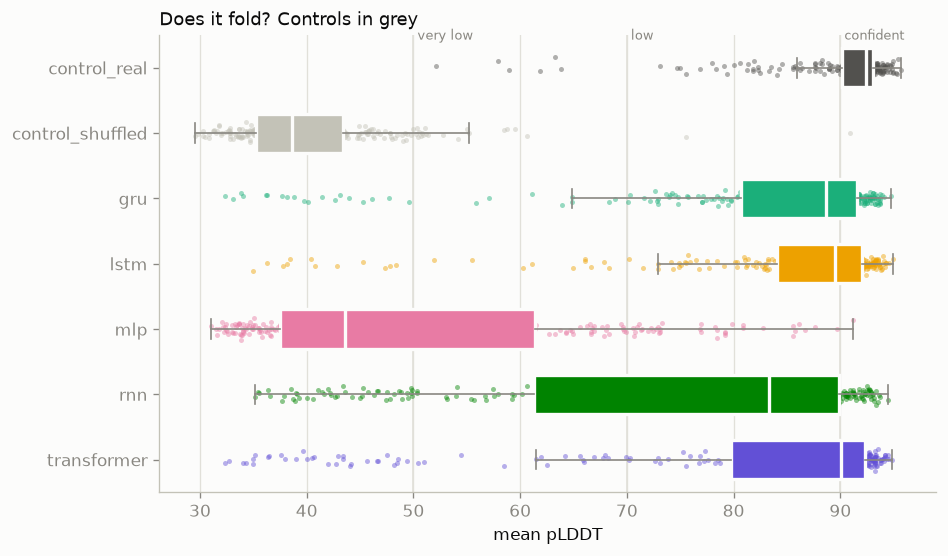

In [6]:
if folded:
    present = [s for s in sets if s in set(table.dropna(subset=["mean_plddt"])["setting"])]
    data = [table.loc[(table["setting"] == s) & table["mean_plddt"].notna(), "mean_plddt"].values
            for s in present]
    cols = [REAL if s == "control_real" else SHUFFLED if s == "control_shuffled"
            else PALETTE[i % len(PALETTE)] for i, s in enumerate(present)]

    fig, ax = plt.subplots(figsize=(8, 0.42 * len(present) + 1.8))
    box = ax.boxplot(data, vert=False, widths=0.6, patch_artist=True, showfliers=False,
                     medianprops=dict(color=SURFACE, lw=2),
                     whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
    for patch, c in zip(box["boxes"], cols):
        patch.set(facecolor=c, edgecolor=SURFACE, linewidth=2)
    for i, (values, c) in enumerate(zip(data, cols), start=1):
        jitter = np.random.default_rng(0).normal(0, 0.055, len(values))
        ax.scatter(values, i + jitter, s=9, color=c, alpha=0.45, linewidths=0)
    ax.set_yticks(range(1, len(present) + 1))
    ax.set_yticklabels(present)
    ax.invert_yaxis()
    ax.set_xlabel("mean pLDDT")
    ax.set_title("Does it fold? Controls in grey", loc="left")
    for threshold, note in ((50, "very low"), (70, "low"), (90, "confident")):
        ax.axvline(threshold, color=GRID, lw=1, zorder=0)
        ax.text(threshold, 0.4, f" {note}", fontsize=8, color=MUTED, va="top")
    ax.grid(axis="x")
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()

Novelty against structure quality. Copying the training set lands on the right with a high
pLDDT and has learned nothing; noise lands on the left with a low one.

One panel per model with the real control in grey behind it, rather than one scatter with seven
colours, which would not be readable.

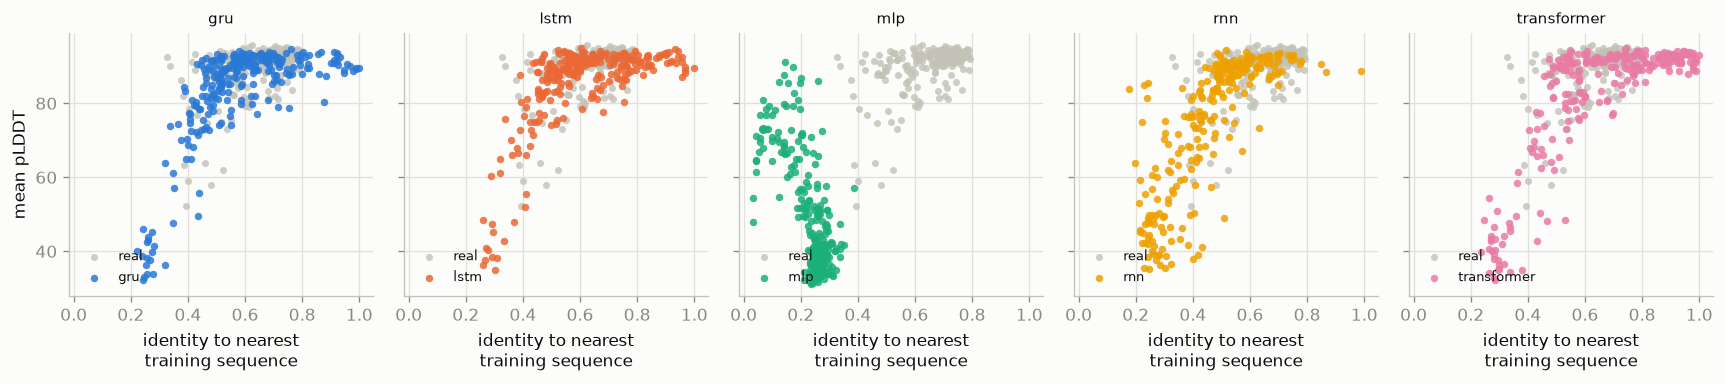

In [7]:
if folded:
    models_only = [s for s in present if not s.startswith("control_")]
    ref = table[(table["setting"] == "control_real") & table["mean_plddt"].notna()]

    fig, axes = plt.subplots(1, max(len(models_only), 1),
                             figsize=(2.9 * max(len(models_only), 1), 3.3),
                             sharex=True, sharey=True)
    axes = np.atleast_1d(axes)
    for i, (ax, name) in enumerate(zip(axes, models_only)):
        group = table[(table["setting"] == name) & table["mean_plddt"].notna()]
        ax.scatter(ref["nearest_identity"], ref["mean_plddt"], s=18, color=SHUFFLED,
                   alpha=0.8, linewidths=0, label="real")
        ax.scatter(group["nearest_identity"], group["mean_plddt"], s=20,
                   color=PALETTE[i % len(PALETTE)], alpha=0.85, linewidths=0, label=name)
        ax.set_title(name, fontsize=9)
        ax.set_xlabel("identity to nearest\ntraining sequence")
        ax.grid(True)
        ax.set_axisbelow(True)
        ax.legend(loc="lower left", fontsize=8)
    axes[0].set_ylabel("mean pLDDT")
    plt.tight_layout()
    plt.show()

## Structures

pLDDT says ESMFold is confident, not that the fold is right. `compare_structures.py` adds
TM-score to real structures, secondary structure, compactness and diversity. CPU only, so it runs
anywhere. List the real control first - the first set provides the reference structures.

In [8]:
sets_arg = " ".join(f"{name}=results/eval/{name}"
                    for name in ["control_real"] + [s for s in sets if s != "control_real"])
print(f"uv run --group eval python eval/compare_structures.py \\\n"
      f"    --out results/structure_comparison \\\n    --sets {sets_arg}")

uv run --group eval python eval/compare_structures.py \
    --out results/structure_comparison \
    --sets control_real=results/eval/control_real control_shuffled=results/eval/control_shuffled gru=results/eval/gru lstm=results/eval/lstm mlp=results/eval/mlp rnn=results/eval/rnn transformer=results/eval/transformer


Worth remembering for the report: none of this measures whether a protein actually works.
pLDDT is a model's opinion of its own output, novelty is distance to the training set, and the
controls bracket plausibility rather than function. The defensible claim is that the samples look
like proteins and are not copies.